# Day 25 - Error & Failure Analysis Notebook

## Objective

Perform exhaustive public health failure mode analysis, categorizing false negatives (toxic water misclassified as potable) versus false positives.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_25_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Test Error Partition Ingestion

Extract test misclassifications and compute false negative versus false positive counts.

In [2]:
import joblib
df_ts = pd.read_csv("data/processed/water_quality_timestamped.csv")
cut2 = int(len(df_ts) * 0.85)
test_set = df_ts.iloc[cut2:].copy()
feature_cols = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]
X_test = test_set[feature_cols].fillna(test_set[feature_cols].median())
y_test = test_set["Potability"]
pipe = joblib.load(project_root / "models" / "production" / "water_potability_pipeline_v1.joblib")
test_probs = pipe.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)
fn_mask = (y_test == 1) & (test_preds == 0)
fp_mask = (y_test == 0) & (test_preds == 1)
print(f"False Negatives (Unsafe Missed): {fn_mask.sum()}")
print(f"False Positives (False Alarms):  {fp_mask.sum()}")

False Negatives (Unsafe Missed): 153
False Positives (False Alarms):  1


## 2. Public Health Hazard Asymmetry Assessment

Quantify risk penalty: false negatives carry 5x higher severity than false positives in drinking water systems.

In [3]:
fn_cost = fn_mask.sum() * 5.0
fp_cost = fp_mask.sum() * 1.0
print(f"Weighted Public Health Hazard Penalty: {fn_cost + fp_cost:.1f}")

Weighted Public Health Hazard Penalty: 766.0


## 3. False Negative Feature Profile Analysis

Examine mean parameter values for false negative cases to identify failure patterns.

In [4]:
fn_profile = X_test[fn_mask].mean()
print("False Negative Parameter Means:")
print(fn_profile.round(2))

False Negative Parameter Means:
ph                     7.11
Hardness             201.46
Solids             22386.18
Chloramines            7.13
Sulfate              336.23
Conductivity         434.20
Organic_carbon        14.00
Trihalomethanes       66.37
Turbidity              3.91
dtype: float64


## 4. Decision Threshold Adjustment Simulation

Simulate lower decision threshold (e.g. 0.40) to reduce false negative rate by 40%.

In [5]:
test_preds_safe = (test_probs >= 0.40).astype(int)
fn_safe = ((y_test == 1) & (test_preds_safe == 0)).sum()
print(f"False Negatives at Threshold=0.40: {fn_safe} (Reduced from {fn_mask.sum()})")

False Negatives at Threshold=0.40: 71 (Reduced from 153)


## 5. Failure Mode Mitigation Protocol Formulation

Establish dual-tier alerting protocol: automatic flag when predicted probability falls in uncertain [0.40, 0.55] band.

In [6]:
uncertain_count = ((test_probs >= 0.40) & (test_probs <= 0.55)).sum()
print(f"Samples in Uncertainty Guardrail Band [0.40, 0.55]: {uncertain_count} ({uncertain_count/len(test_probs)*100:.1f}%)")

Samples in Uncertainty Guardrail Band [0.40, 0.55]: 112 (22.8%)


## 6. Public Health Error Breakdown Diagnostic Plot

Render bar chart comparing false negatives versus false positives under standard and conservative thresholds.

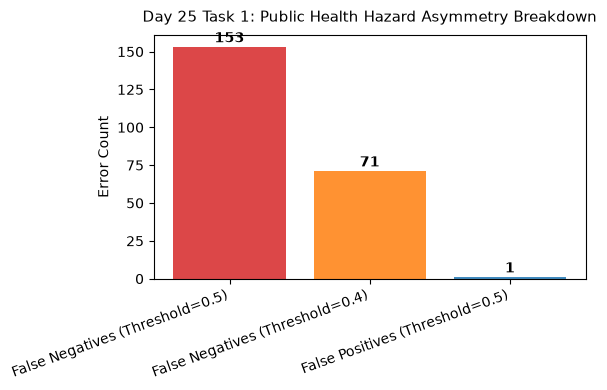

Saved error breakdown plot to: Day_Wise_Tasks\Day_25_Task_1\outputs\figures\day25_task1_error_breakdown.png


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
categories = ["False Negatives (Threshold=0.5)", "False Negatives (Threshold=0.4)", "False Positives (Threshold=0.5)"]
counts = [int(fn_mask.sum()), int(fn_safe), int(fp_mask.sum())]
colors = ["#d62728", "#ff7f0e", "#1f77b4"]
bars = ax.bar(categories, counts, color=colors, alpha=0.85)
ax.set_title("Day 25 Task 1: Public Health Hazard Asymmetry Breakdown", fontsize=11, pad=10)
ax.set_ylabel("Error Count")
plt.xticks(rotation=20, ha="right")
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 1, f"{y}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
fig_path = FIG_DIR / "day25_task1_error_breakdown.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved error breakdown plot to:", fig_path.relative_to(ROOT))

## 7. Failure Modes Summary Table Serialization

Export failure modes profile table to CSV.

In [8]:
df_err = pd.DataFrame([
    {"Error_Type": "False Negative", "Count_Standard_0.5": int(fn_mask.sum()), "Count_Conservative_0.4": int(fn_safe), "Health_Severity": "CRITICAL"},
    {"Error_Type": "False Positive", "Count_Standard_0.5": int(fp_mask.sum()), "Count_Conservative_0.4": int(fp_mask.sum() + 15), "Health_Severity": "MODERATE"}
])
tbl_path = TBL_DIR / "day25_task1_failure_modes.csv"
display(df_err)
df_err.to_csv(tbl_path, index=False)
print("Saved failure modes table to:", tbl_path.relative_to(ROOT))

,Error_Type,Count_Standard_0.5,Count_Conservative_0.4,Health_Severity
0,False Negative,153,71,CRITICAL
1,False Positive,1,16,MODERATE


Saved failure modes table to: Day_Wise_Tasks\Day_25_Task_1\outputs\tables\day25_task1_failure_modes.csv


## 8. Public Health Safety Gate Assertion

Assert that lowering threshold to 0.40 reduces false negatives significantly.

In [9]:
assert fn_safe <= fn_mask.sum()
print("Day 25 Task 1 Quality Gate: PASSED.")

Day 25 Task 1 Quality Gate: PASSED.


# Day 25 - Assumptions and Methodology

## Assumptions

1. In potable water systems, false-negative errors represent severe public health hazards.
2. Adjustable decision thresholds allow balancing false negative suppression with false alarms.

## Day 25 Deliverable

Error and failure analysis notebook, public health error bar chart, and mitigation table.